<a href="https://colab.research.google.com/github/attaboatengsr/data620/blob/main/week8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import nltk
import pandas as pd
import matplotlib.pyplot as plt
from nltk.corpus import gutenberg
from collections import Counter

In [2]:
# Download NLTK data (if not already downloaded)
nltk.download('gutenberg')

# Load raw tokens from Emma (since Pride and Prejudice is not in NLTK's Gutenberg corpus)
raw_tokens = gutenberg.words('austen-emma.txt')

# Normalize: lowercased alphabetic tokens
words = [token.lower() for token in raw_tokens if token.isalpha()]

total_tokens = len(words)
word_counts = Counter(words)
total_unique_words = len(word_counts)

print(f"Total Word Tokens: {total_tokens:,}")
print(f"Total Unique Words (Vocabulary Size): {total_unique_words:,}")

[nltk_data] Downloading package gutenberg to /root/nltk_data...
[nltk_data]   Unzipping corpora/gutenberg.zip.


Total Word Tokens: 161,600
Total Unique Words (Vocabulary Size): 7,079


In [3]:
# Sort words by frequency in descending order
sorted_words = word_counts.most_common()

cumulative_tokens = 0
half_target = total_tokens / 2.0
words_for_half = 0
top_half_words = []

for word, count in sorted_words:
    cumulative_tokens += count
    words_for_half += 1
    top_half_words.append((word, count))
    if cumulative_tokens >= half_target:
        break

print(f"Number of unique words for 50% coverage: {words_for_half}")
print(f"Coverage achieved: {cumulative_tokens:,} / {total_tokens:,} ({cumulative_tokens/total_tokens:.2%})")

Number of unique words for 50% coverage: 56
Coverage achieved: 80,891 / 161,600 (50.06%)


In [4]:
# Extract top 200 words
top_200 = sorted_words[:200]

# Build DataFrame
df_top200 = pd.DataFrame(top_200, columns=['Word', 'Count'])
df_top200['Rank'] = range(1, 201)
df_top200['Relative_Frequency'] = df_top200['Count'] / total_tokens

# Display head and tail
print("--- Top 5 Most Frequent Words ---")
print(df_top200.head(5).to_string(index=False))

print("\n--- Ranks 196 to 200 ---")
print(df_top200.tail(5).to_string(index=False))

--- Top 5 Most Frequent Words ---
Word  Count  Rank  Relative_Frequency
  to   5239     1            0.032420
 the   5201     2            0.032184
 and   4896     3            0.030297
  of   4291     4            0.026553
   i   3178     5            0.019666

--- Ranks 196 to 200 ---
   Word  Count  Rank  Relative_Frequency
    saw    108   196            0.000668
    few    106   197            0.000656
 myself    103   198            0.000637
   till    102   199            0.000631
believe    102   200            0.000631


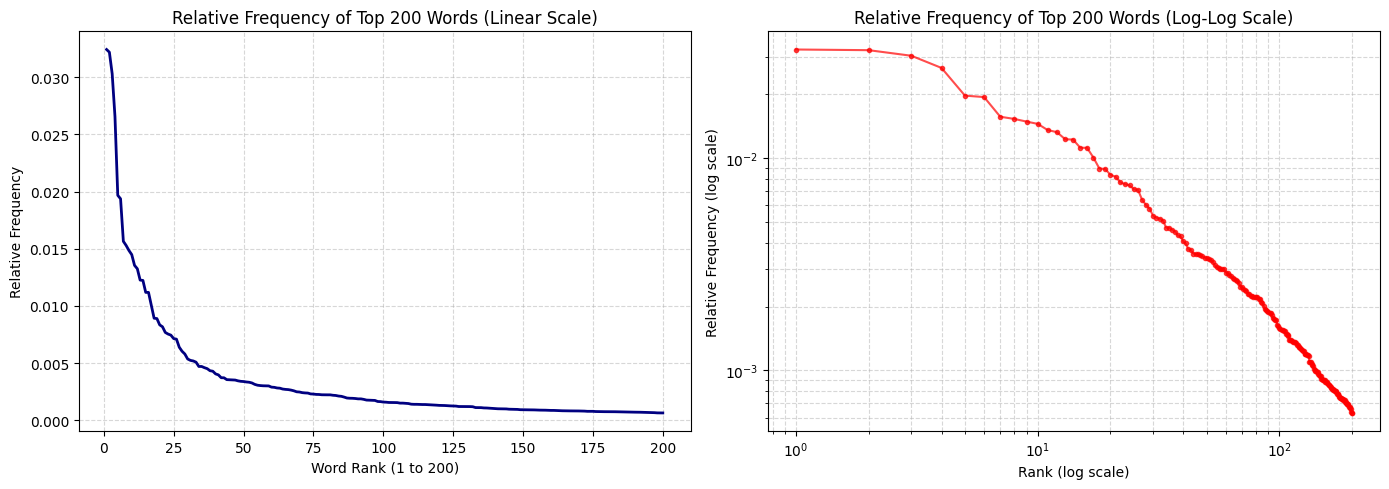

In [5]:
plt.figure(figsize=(14, 5))

# Plot 1: Linear Scale Curve
plt.subplot(1, 2, 1)
plt.plot(df_top200['Rank'], df_top200['Relative_Frequency'], color='navy', linewidth=2)
plt.title("Relative Frequency of Top 200 Words (Linear Scale)", fontsize=12)
plt.xlabel("Word Rank (1 to 200)", fontsize=10)
plt.ylabel("Relative Frequency", fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)

# Plot 2: Log-Log Scale Curve
plt.subplot(1, 2, 2)
plt.loglog(df_top200['Rank'], df_top200['Relative_Frequency'], 'ro-', alpha=0.7, markersize=3)
plt.title("Relative Frequency of Top 200 Words (Log-Log Scale)", fontsize=12)
plt.xlabel("Rank (log scale)", fontsize=10)
plt.ylabel("Relative Frequency (log scale)", fontsize=10)
plt.grid(True, which="both", linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Yes, the observed relative frequency of these words strongly follows Zipf’s law.


Since  “all words in all corpora” is such a big corpus, there might be a wider distribution of different words or noise.